# Тест MELD Graph на открытом датасете OpenNeuro ds004199 (Bonn, FCD II)

Ноутбук делает полный цикл:

1. проверяет окружение (FreeSurfer 7.2, лицензии, PyTorch/CUDA в env `meld_graph`, RAM, диск);
2. скачивает данные ds004199;
3. раскладывает их в формат MELD (`input/<ID>/T1`, `input/<ID>/FLAIR`);
4. запускает пайплайн MELD Graph по одному субъекту за раз (с возобновлением: готовые субъекты пропускаются);
5. считает метрики: чувствительность по пациентам (строгую — перекрытие с маской, и с допуском `BOUNDARY_MM`), специфичность на контролях, число ложных кластеров, Dice;

# **Результаты**

**Что сделано.** MELD Graph прогнан на 6 субъектах открытого датасета OpenNeuro ds004199 (Bonn, FCD II): 3 пациента с FCD и маской поражения, 3 здоровых контроля. Режим: только T1 (без FLAIR), без гармонизации, FreeSurfer 7.2, предсказание на CPU. Пайплайн отработал на всех 6 без ошибок, около 3 ч на субъекта (почти всё время занимает FreeSurfer). 

**Результаты.**

| Показатель | Значение |
|---|---|
| Пациенты, у которых найдено поражение | **2 из 3** (sub-00059, sub-00142); у sub-00123 нет ни одного кластера |
| Кластеры у пациентов | все 4 лежат на маске, ложных нет |
| Dice с маской | 0.31 и 0.50 у найденных; медиана по 3 пациентам 0.31 |
| Контроли без находок (специфичность) | **1 из 3**; у sub-00137 и sub-00157 по 2 ложных кластера |

**Вывод.** Пайплайн рабочий и воспроизводимый. По одному T1 модель находит часть поражений FCD II и точно их локализует, но у здоровых даёт много ложных срабатываний. На 3 + 3 субъектах это только проверка работоспособности, а не оценка качества: 95% ДИ чувствительности 0.21–0.94, специфичности 0.06–0.79.

## 1. Настройки

In [ ]:
import os, sys, json, time, shutil, subprocess, signal, threading, re, csv
import datetime as dt
import urllib.request, urllib.parse
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd

HOME = Path.home()
PROJECT_DIR = HOME / "projects" / "mri"
MELD_DIR    = PROJECT_DIR / "meld_graph"                  
MELD_DATA   = PROJECT_DIR / "meld_data"                   
RAW_DIR     = PROJECT_DIR / "datasets" / "ds004199"      
WORK_DIR    = PROJECT_DIR / "meld_eval"                   # логи, таблицы, картинки этого ноутбука
CONDA_SH    = HOME / "miniconda3" / "etc" / "profile.d" / "conda.sh"
FREESURFER_HOME = Path(os.environ.get("FREESURFER_HOME") or (HOME / "freesurfer"))  # FreeSurfer 7.2.0
FASTSURFER_HOME = HOME / "FastSurfer"                   

DATASET_ID = "ds004199"

# --- объём прогона
N_PATIENTS = 3            # пилот
N_CONTROLS = 3
RUN_ALL    = False        # True -> все субъекты датасета
RANDOM_SEED = 42

# --- режим MELD
USE_FLAIR      = False    # MELD рекомендует основным считать прогон только по T1; FLAIR -> второй прогон
USE_FASTSURFER = False    # FastSurfer грузит GPU сильнее всего; FreeSurfer работает на CPU
MELD_ON_GPU    = False    # предсказание MELD на GPU требует >13 ГБ свободной видеопамяти (на общей A4000 ловит CUDA OOM);
                          # на CPU оно идёт несколько минут и не греет GPU. True — только если карта свободна целиком
MIN_FREE_VRAM_MB = 15000  # минимум свободной видеопамяти для MELD_ON_GPU=True
FS_THREADS     = 4        # потоки FreeSurfer на субъекта
MIN_FREE_RAM_GB = 22      # MELD на этапе предсказания может съесть ~20 ГБ RAM

# --- GPU и температура
GPU_INDEX   = None       
TEMP_PAUSE  = 80          
TEMP_RESUME = 72          
TEMP_LIMIT  = 85          
POLL_SEC    = 2.0

# --- оценка
BOUNDARY_MM = 20.0        # допуск: кластер в пределах N мм от маски считается попаданием (0 -> только перекрытие)

for d in (RAW_DIR, WORK_DIR, WORK_DIR / "logs", WORK_DIR / "roi_in_t1", WORK_DIR / "figures"):
    d.mkdir(parents=True, exist_ok=True)

RUN_TAG = "FL" if USE_FLAIR else "T1"
print("MELD_DIR:", MELD_DIR, "| MELD_DATA:", MELD_DATA, "| режим:", RUN_TAG)

MELD_DIR: /home/trocinskayayv/projects/mri/meld_graph | MELD_DATA: /home/trocinskayayv/projects/mri/meld_data | режим: T1


## 2. Проверка окружения

In [ ]:
problems = []

def check(cond, ok_msg, bad_msg):
    print(("  OK   " if cond else "  FAIL ") + (ok_msg if cond else bad_msg))
    if not cond:
        problems.append(bad_msg)

check((MELD_DIR / "meldgraph.sh").exists(), "meldgraph.sh найден", f"нет {MELD_DIR}/meldgraph.sh")
check((MELD_DIR / "license.txt").exists(), "license.txt (FreeSurfer) в папке meld_graph", "скопируйте license.txt в папку meld_graph")
check((MELD_DIR / "meld_license.txt").exists(), "meld_license.txt в папке meld_graph", "скопируйте meld_license.txt в папку meld_graph")
check(CONDA_SH.exists(), f"conda.sh: {CONDA_SH}", f"не найден {CONDA_SH}")

stamp = FREESURFER_HOME / "build-stamp.txt"
fs_ver = stamp.read_text().strip() if stamp.exists() else ""
check("7.2" in fs_ver, f"FreeSurfer: {fs_ver}", f"нужен FreeSurfer 7.2.x в {FREESURFER_HOME} (найдено: '{fs_ver or 'ничего'}'); 7.3+ MELD не поддерживает")
check(shutil.which("tcsh") is not None, "tcsh есть", "нет tcsh: recon-all")
check(shutil.which("bc") is not None, "bc есть", "нет bc")

cfg = MELD_DIR / "meld_config.ini"
if cfg.exists():
    print("  OK   meld_config.ini:\n" + "\n".join("         " + l for l in cfg.read_text().splitlines()))
else:
    problems.append("нет meld_config.ini")
    print("  FAIL нет meld_config.ini")

# RAM / диск
mem = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo")}
avail_gb = mem["MemAvailable"] / 1024**2
print(f"  INFO RAM доступно: {avail_gb:.1f} ГБ")
du = shutil.disk_usage(PROJECT_DIR)
print(f"  INFO диск свободно: {du.free/1024**3:.0f} ГБ (на 1 субъекта нужно ~0.5–1 ГБ вывода FreeSurfer+MELD)")

print("\nИТОГ:", "всё готово" if not problems else f"{len(problems)} проблема")

  OK   meldgraph.sh найден
  OK   license.txt (FreeSurfer) в папке meld_graph
  OK   meld_license.txt в папке meld_graph
  OK   conda.sh: /home/trocinskayayv/miniconda3/etc/profile.d/conda.sh
  OK   FreeSurfer: freesurfer-linux-centos7_x86_64-7.2.0-20210720-aa8f76b
  OK   tcsh есть (нужен recon-all)
  OK   bc есть
  OK   meld_config.ini:
         [DEFAULT]
         meld_data_path = /home/trocinskayayv/projects/mri/meld_data
         
         [develop]
         base_path = %(meld_data_path)s/output/preprocessed_surf_data
         experiment_path = %(meld_data_path)s/models
         fs_subjects_path = %(meld_data_path)s/output/fs_outputs
         meld_params_path = %(meld_data_path)s/meld_params
         
  INFO RAM доступно: 117.5 ГБ
  INFO диск свободно: 129 ГБ (на 1 субъекта нужно ~0.5–1 ГБ вывода FreeSurfer+MELD)

ИТОГ: всё готово


## 3. Выбор GPU и сторож температуры

In [ ]:
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"

def query_gpus():
    q = "index,name,temperature.gpu,utilization.gpu,memory.used,memory.total,power.draw"
    out = subprocess.run(["nvidia-smi", f"--query-gpu={q}", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True, check=True).stdout
    rows = []
    for line in out.strip().splitlines():
        idx, name, t, u, mu, mt, p = [x.strip() for x in line.split(",")]
        rows.append(dict(index=int(idx), name=name, temp=int(t), util=int(u),
                         mem_used=int(mu), mem_total=int(mt), power=p))
    return pd.DataFrame(rows)

gpus = query_gpus()
display(gpus)
if GPU_INDEX is None:
    score = gpus.mem_used / gpus.mem_total * 100 + gpus.util + gpus.temp * 0.5
    GPU_INDEX = int(gpus.loc[score.idxmin(), "index"])
free_mb = int(gpus.set_index("index").loc[GPU_INDEX, "mem_total"] - gpus.set_index("index").loc[GPU_INDEX, "mem_used"])
print(f"Свободно видеопамяти на GPU {GPU_INDEX}: {free_mb} МБ")
if MELD_ON_GPU and free_mb < MIN_FREE_VRAM_MB:
    print(f"Меньше {MIN_FREE_VRAM_MB} МБ — предсказание MELD будет на CPU")
    MELD_ON_GPU = False
GPU_VISIBLE = MELD_ON_GPU or USE_FASTSURFER
print("MELD видит GPU:" , GPU_VISIBLE, "(CPU-режим)" if not GPU_VISIBLE else "")
print("Используем GPU", GPU_INDEX)
if int(gpus.set_index("index").loc[GPU_INDEX, "temp"]) >= TEMP_RESUME:
    print("Остановка", TEMP_RESUME, "°C")

,index,name,temp,util,mem_used,mem_total,power
0,0,NVIDIA RTX A4000,62,0,0,15352,44.42
1,1,NVIDIA RTX A4000,61,2,0,15352,41.42
2,2,NVIDIA RTX A4000,60,2,0,15352,35.84


Свободно видеопамяти на GPU 0: 15352 МБ
MELD видит GPU: False (CPU-режим)
Используем GPU 0


In [ ]:
class GpuGuard:
    """Опрашивает температуру GPU и ставит на паузу/возобновляет зарегистрированные группы процессов."""

    def __init__(self, gpu, pause_at, resume_at, limit, poll=2.0, log_path=None):
        assert resume_at < pause_at <= limit
        self.gpu, self.pause_at, self.resume_at, self.limit, self.poll = gpu, pause_at, resume_at, limit, poll
        self.log_path = Path(log_path) if log_path else None
        self.procs, self.paused, self.max_temp = [], False, 0
        self.n_pauses, self.paused_sec, self._pause_t0 = 0, 0.0, None
        self._lock, self._stop, self._thread = threading.Lock(), threading.Event(), None
        self.last = None

    def read(self):
        out = subprocess.run(["nvidia-smi", "-i", str(self.gpu),
                              "--query-gpu=temperature.gpu,utilization.gpu,memory.used,power.draw",
                              "--format=csv,noheader,nounits"],
                             capture_output=True, text=True, timeout=15, check=True).stdout.strip()
        t, u, m, p = [x.strip() for x in out.split(",")]
        return int(t), u, m, p

    def _signal(self, sig):
        with self._lock:
            for pr in list(self.procs):
                if pr.poll() is None:
                    try:
                        os.killpg(pr.pid, sig)        # pgid == pid (start_new_session=True)
                    except ProcessLookupError:
                        pass

    def _set_paused(self, flag, temp, reason=""):
        if flag and not self.paused:
            self._signal(signal.SIGSTOP); self.paused = True
            self.n_pauses += 1; self._pause_t0 = time.time()
            print(f"[{dt.datetime.now():%H:%M:%S}] GPU{self.gpu} {temp}°C ≥ {self.pause_at} - пауза {reason}")
        elif not flag and self.paused:
            self._signal(signal.SIGCONT); self.paused = False
            self.paused_sec += time.time() - (self._pause_t0 or time.time())
            print(f"[{dt.datetime.now():%H:%M:%S}] GPU{self.gpu} {temp}°C ≤ {self.resume_at} - продолжаем")

    def _loop(self):
        fails = 0
        while not self._stop.is_set():
            try:
                t, u, m, p = self.read(); fails = 0
            except Exception as e:
                fails += 1
                if fails >= 3:  
                    self._set_paused(True, "?", f"(nvidia-smi не отвечает: {e})")
                time.sleep(self.poll); continue
            self.last = (t, u, m, p)
            self.max_temp = max(self.max_temp, t)
            if t >= self.pause_at:
                self._set_paused(True, t)
            elif self.paused and t <= self.resume_at:
                self._set_paused(False, t)
            if t >= self.limit:
                print(f"GPU{self.gpu} процессы на паузе.")
            if self.log_path:
                new = not self.log_path.exists()
                with open(self.log_path, "a", newline="") as f:
                    w = csv.writer(f)
                    if new:
                        w.writerow(["time", "temp", "util", "mem_used", "power", "paused", "n_procs"])
                    w.writerow([dt.datetime.now().isoformat(timespec="seconds"), t, u, m, p,
                                int(self.paused), sum(pr.poll() is None for pr in self.procs)])
            time.sleep(self.poll)

    def start(self):
        if self._thread and self._thread.is_alive():
            return self
        self._stop.clear()
        self._thread = threading.Thread(target=self._loop, daemon=True); self._thread.start()
        return self

    def stop(self):
        self._signal(signal.SIGCONT); self.paused = False
        self._stop.set()

    def register(self, proc):
        with self._lock:
            self.procs.append(proc)
        if self.paused:                   
            os.killpg(proc.pid, signal.SIGSTOP)

    def unregister(self, proc):
        with self._lock:
            if proc in self.procs:
                self.procs.remove(proc)

    def wait_until_cool(self, check_every=10):
        t = self.read()[0]
        while t > self.resume_at:
            print(f"GPU{self.gpu} {t}°C — ждём остывания до {self.resume_at}°C…"); time.sleep(check_every)
            t = self.read()[0]


try:
    guard.stop()                              
except NameError:
    pass
guard = GpuGuard(GPU_INDEX, TEMP_PAUSE, TEMP_RESUME, TEMP_LIMIT, POLL_SEC,
                 log_path=WORK_DIR / "logs" / "gpu_temperature.csv").start()
time.sleep(POLL_SEC * 2)
print("Сторож запущен, последний замер (temp, util, mem, power):", guard.last)

Сторож запущен, последний замер (temp, util, mem, power): (62, '2', '0', '44.40')


## 4. Запуск команд MELD под контролем сторожа

In [ ]:
def shell_prefix(gpu_visible=None):
    if gpu_visible is None:
        gpu_visible = GPU_VISIBLE
    lines = [
        f'source "{CONDA_SH}"',
        f'export FREESURFER_HOME="{FREESURFER_HOME}"',
        'source "$FREESURFER_HOME/SetUpFreeSurfer.sh" > /dev/null || true',
        f'export PATH="$PATH:{HOME}/miniconda3/envs/tools/bin"',   # tcsh из conda (скрипты FreeSurfer ищут его через PATH)
        f'export FS_LICENSE="{MELD_DIR / "license.txt"}"',
        'export CUDA_DEVICE_ORDER=PCI_BUS_ID',
        f'export CUDA_VISIBLE_DEVICES={GPU_INDEX if gpu_visible else ""}',
        f'export OMP_NUM_THREADS={FS_THREADS}',
        f'export ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS={FS_THREADS}',
    ]
    if USE_FASTSURFER:
        lines.append(f'export FASTSURFER_HOME="{FASTSURFER_HOME}"')
    lines.append(f'cd "{MELD_DIR}"')
    return "\n".join(lines) + "\n"


def wait_for_ram(min_gb=MIN_FREE_RAM_GB, max_wait_min=120):
    t0 = time.time()
    while True:
        mem = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo")}
        avail = mem["MemAvailable"] / 1024**2
        if avail >= min_gb:
            return avail
        if time.time() - t0 > max_wait_min * 60:
            print(f"RAM {avail:.1f} ГБ < {min_gb} ГБ уже {max_wait_min} мин — запускаем всё равно")
            return avail
        print(f"RAM {avail:.1f} ГБ < {min_gb} ГБ, ждём…"); time.sleep(60)


def run_guarded(cmd, log_file, cwd=MELD_DIR):
    """Запускает bash-команду в отдельной группе процессов, регистрирует её у сторожа."""
    guard.wait_until_cool()
    log_file = Path(log_file)
    with open(log_file, "a") as lf:
        lf.write(f"\n===== {dt.datetime.now().isoformat(timespec='seconds')} :: {cmd}\n"); lf.flush()
        proc = subprocess.Popen(["bash", "-c", shell_prefix() + cmd], cwd=cwd,
                                stdout=lf, stderr=subprocess.STDOUT, start_new_session=True)
        guard.register(proc)
        try:
            rc = proc.wait()
        except KeyboardInterrupt:
            print("Прерывание: останавливаем процесс…")
            for sig in (signal.SIGCONT, signal.SIGTERM):
                try:
                    os.killpg(proc.pid, sig)
                except ProcessLookupError:
                    pass
            proc.wait(); raise
        finally:
            guard.unregister(proc)
    return rc


def tail(path, n=30):
    try:
        return "".join(Path(path).read_text(errors="ignore").splitlines(True)[-n:])
    except FileNotFoundError:
        return ""


# Проверка PyTorch/CUDA внутри env meld_graph
r = subprocess.run(["bash", "-c", shell_prefix(gpu_visible=True) + 'conda activate meld_graph && python -c "'
                    'import torch, torch_geometric, torch_scatter, meld_graph; '
                    'print(torch.__version__, torch.version.cuda, torch.cuda.is_available(), torch.cuda.device_count(), '
                    'torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)"'],
                   capture_output=True, text=True)
print(r.stdout or r.stderr[-2000:])

# Какие флаги поддерживает установленная версия пайплайна
r = subprocess.run(["bash", "-c", shell_prefix() + "./meldgraph.sh new_pt_pipeline.py -h"], capture_output=True, text=True)
HELP = r.stdout + r.stderr
SUPPORTED = {f: (f in HELP) for f in ["--threads", "--fastsurfer", "--skip_feature_plotting", "--no_report"]}
print("Флаги new_pt_pipeline.py:", SUPPORTED)

1.10.0+cu113 11.3 True 1 NVIDIA RTX A4000

Флаги new_pt_pipeline.py: {'--threads': True, '--fastsurfer': True, '--skip_feature_plotting': True, '--no_report': True}


## 5. Официальный тест установки `./meldgraph.sh pytest`

In [6]:
RUN_PYTEST = False
if RUN_PYTEST:
    log = WORK_DIR / "logs" / "pytest.log"
    t0 = time.time()
    rc = run_guarded("./meldgraph.sh pytest -s", log)
    print(f"pytest rc={rc}, {(time.time()-t0)/60:.1f} мин, max GPU {guard.max_temp}°C")
    print(tail(log, 40))

## 6. Загрузка ds004199 из открытого S3-бакета OpenNeuro

Скачиваются только нужные субъекты; уже скачанные файлы пропускаются.

In [7]:
S3 = "https://s3.amazonaws.com/openneuro.org"

def s3_list(prefix):
    keys, token = [], None
    while True:
        params = {"list-type": "2", "prefix": prefix}
        if token:
            params["continuation-token"] = token
        with urllib.request.urlopen(f"{S3}?{urllib.parse.urlencode(params)}", timeout=60) as r:
            root = ET.fromstring(r.read())
        ns = {"s": root.tag.split("}")[0].strip("{")}
        for c in root.findall("s:Contents", ns):
            keys.append((c.find("s:Key", ns).text, int(c.find("s:Size", ns).text)))
        if root.findtext("s:IsTruncated", default="false", namespaces=ns) == "true":
            token = root.findtext("s:NextContinuationToken", namespaces=ns)
        else:
            return keys

def s3_download(prefix, only_top_level=False):
    n_new = 0
    for key, size in s3_list(prefix):
        rel = key[len(DATASET_ID) + 1:]
        if not rel or (only_top_level and "/" in rel):
            continue
        dst = RAW_DIR / rel
        if dst.exists() and dst.stat().st_size == size:
            continue
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(dst.name + ".part")
        with urllib.request.urlopen(f"{S3}/{urllib.parse.quote(key)}", timeout=300) as r, open(tmp, "wb") as f:
            shutil.copyfileobj(r, f, length=1 << 20)
        tmp.rename(dst); n_new += 1
    return n_new

print("Новых файлов верхнего уровня:", s3_download(f"{DATASET_ID}/", only_top_level=True))
print(sorted(p.name for p in RAW_DIR.iterdir() if p.is_file()))

Новых файлов верхнего уровня: 0
['.bidsignore', '.gitattributes', 'CHANGES', 'README', 'dataset_description.json', 'participants.json', 'participants.tsv']


In [8]:
part = pd.read_csv(RAW_DIR / "participants.tsv", sep="\t")
print(part.shape); display(part.head(10)); print(list(part.columns))
if (RAW_DIR / "participants.json").exists():
    print(json.dumps(json.load(open(RAW_DIR / "participants.json")), ensure_ascii=False, indent=1)[:3000])

(170, 19)


,participant_id,group,sex,age_epilepsyonset,age_scan,mri_diagnosis,map,spect,pet,invasive_EEG,op,age_op,histopathology,1year_outcome,latest_outcome,time_follow-up,hemisphere,lobe,split
0,sub-00058,fcd,M,1.0,4,suspicion,0.0,0.0,0.0,0.0,1,4.0,IIb,IA,IA,2.0,L,FL,train
1,sub-00043,fcd,F,2.0,4,suspicion,1.0,0.0,0.0,0.0,1,4.0,IIa,IA,IA,3.0,R,FL,test
2,sub-00133,fcd,F,3.0,7,suspicion,1.0,0.0,1.0,0.0,0,NaN,NaN,NaN,NaN,NaN,R,TL,train
3,sub-00120,fcd,M,7.0,8,suspicion,1.0,0.0,1.0,0.0,1,8.0,IIb,IA,IA,7.0,L,FL,train
4,sub-00060,fcd,F,2.0,13,suspicion,0.0,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,R,FL,train
5,sub-00047,fcd,M,1.0,7,suspicion,1.0,0.0,0.0,1.0,1,7.0,IIa,IVB,IVB,2.0,L,PL,train
6,sub-00132,fcd,M,1.0,6,suspicion,1.0,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,R,FL,train
7,sub-00059,fcd,M,4.0,5,suspicion,1.0,0.0,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,L,FL,train
8,sub-00050,fcd,M,5.0,9,suspicion,0.0,0.0,0.0,1.0,0,NaN,NaN,NaN,NaN,NaN,L,FL,train
9,sub-00027,fcd,M,8.0,8,suspicion,0.0,0.0,0.0,0.0,1,9.0,IIb,IA,IA,2.0,R,PL,train


['participant_id', 'group', 'sex', 'age_epilepsyonset', 'age_scan', 'mri_diagnosis', 'map', 'spect', 'pet', 'invasive_EEG', 'op', 'age_op', 'histopathology', '1year_outcome', 'latest_outcome', 'time_follow-up', 'hemisphere', 'lobe', 'split']
{
 "group": {
  "Description": "the group a person belongs to",
  "Levels": {
   "fcd": "person with epilepsy, diagnosed with an FCD",
   "hc": "healthy control"
  }
 },
 "sex": {
  "Description": "sex of the participant",
  "Levels": {
   "M": "male",
   "F": "female"
  }
 },
 "age_epilepsyonset": {
  "Description": "categorized age in years at the time of the first seizure",
  "Levels": {
   "1": "0-5 years",
   "2": "6-10 years",
   "3": "11-15 years",
   "4": "16-20 years",
   "5": "21-25 years",
   "6": "26-30 years",
   "7": "31-35 years",
   "8": "36-40 years",
   "9": "41-45 years",
   "10": "46-50 years",
   "11": "51-55 years",
   "12": "56-60 years",
   "13": "61-65 years"
  }
 },
 "age_scan": {
  "Description": "categorized age in years

Ниже группа (пациент/контроль) определяется эвристически. 

In [ ]:
GROUP_COL   = None                     
PATIENT_PAT = r"fcd|patient|epilep"
CONTROL_PAT = r"control|^hc$|healthy"

if GROUP_COL is None:
    for c in part.columns:
        v = part[c].astype(str).str.lower().str.strip()
        if (v.str.contains(PATIENT_PAT) | v.str.contains(CONTROL_PAT)).mean() > 0.9:
            GROUP_COL = c; break
assert GROUP_COL is not None, "Не найдена колонка group"

g = part[GROUP_COL].astype(str).str.lower().str.strip()
part["is_patient"] = g.str.contains(PATIENT_PAT)
part["is_control"] = g.str.contains(CONTROL_PAT) & ~part["is_patient"]
print("Колонка группы:", GROUP_COL); print(part.groupby([GROUP_COL, "is_patient", "is_control"]).size())

pat_ids = part.loc[part.is_patient, "participant_id"].tolist()
con_ids = part.loc[part.is_control, "participant_id"].tolist()
rng = np.random.default_rng(RANDOM_SEED)
if RUN_ALL:
    sel_pat, sel_con = pat_ids, con_ids
else:
    sel_pat = sorted(rng.choice(pat_ids, size=min(N_PATIENTS, len(pat_ids)), replace=False).tolist())
    sel_con = sorted(rng.choice(con_ids, size=min(N_CONTROLS, len(con_ids)), replace=False).tolist())
print("Пациенты:", sel_pat); print("Контроли:", sel_con)

Колонка группы: group
group  is_patient  is_control
fcd    True        False         85
hc     False       True          85
dtype: int64
Пациенты: ['sub-00059', 'sub-00123', 'sub-00142']
Контроли: ['sub-00017', 'sub-00137', 'sub-00157']


In [10]:
for s in sel_pat + sel_con:
    n = s3_download(f"{DATASET_ID}/{s}/")
    files = sorted(p.relative_to(RAW_DIR / s).as_posix() for p in (RAW_DIR / s).rglob("*.nii*"))
    print(f"{s}: +{n} файлов; nifti: {files}")

sub-00059: +0 файлов; nifti: ['anat/sub-00059_acq-sag111_T1w.nii.gz', 'anat/sub-00059_acq-tse3dvfl_FLAIR.nii.gz', 'anat/sub-00059_acq-tse3dvfl_FLAIR_roi.nii.gz']
sub-00123: +0 файлов; nifti: ['anat/sub-00123_acq-sag111_T1w.nii.gz', 'anat/sub-00123_acq-tse3dvfl_FLAIR.nii.gz', 'anat/sub-00123_acq-tse3dvfl_FLAIR_roi.nii.gz']
sub-00142: +0 файлов; nifti: ['anat/sub-00142_acq-T2sel_FLAIR.nii.gz', 'anat/sub-00142_acq-T2sel_FLAIR_roi.nii.gz', 'anat/sub-00142_acq-iso08_T1w.nii.gz']
sub-00017: +0 файлов; nifti: ['anat/sub-00017_acq-T2sel_FLAIR.nii.gz', 'anat/sub-00017_acq-iso08_T1w.nii.gz']
sub-00137: +0 файлов; nifti: ['anat/sub-00137_acq-T2sel_FLAIR.nii.gz', 'anat/sub-00137_acq-iso08_T1w.nii.gz']
sub-00157: +0 файлов; nifti: ['anat/sub-00157_acq-T2sel_FLAIR.nii.gz', 'anat/sub-00157_acq-iso08_T1w.nii.gz']


## 7. Перевод в формат MELD

ID без спецсимволов и не чисто числовой (`B00001T1` / `B00001FL`), чтобы прогоны «только T1» и «T1+FLAIR» не перезаписывали друг друга.

In [ ]:
def pick(files, must, exclude=("roi", "label", "mask", "lesion", "dseg")):
    c = [f for f in files if must.lower() in f.name.lower() and not any(x in f.name.lower() for x in exclude)]
    return sorted(c)

def find_roi(files):
    return sorted(f for f in files if any(x in f.name.lower() for x in ("roi", "lesion", "label", "mask")))

INPUT_DIR = MELD_DATA / "input"
INPUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []
for s in sel_pat + sel_con:
    nii = [p for p in (RAW_DIR / s).rglob("*.nii*") if p.is_file()]
    t1s, fls, rois = pick(nii, "T1w"), pick(nii, "FLAIR"), find_roi(nii)
    if not t1s:
        print(f"{s}: нет T1w — пропуск"); continue
    if len(t1s) > 1: print(f"{s}: несколько T1w, беру {t1s[0].name}")
    mid = "B" + re.sub(r"\D", "", s) + RUN_TAG
    sd = INPUT_DIR / mid
    (sd / "T1").mkdir(parents=True, exist_ok=True)
    for old in (sd / "T1").glob("*"): old.unlink()
    shutil.copy2(t1s[0], sd / "T1" / f"{mid}_T1.nii.gz")
    if USE_FLAIR and fls:
        (sd / "FLAIR").mkdir(exist_ok=True)
        for old in (sd / "FLAIR").glob("*"): old.unlink()
        shutil.copy2(fls[0], sd / "FLAIR" / f"{mid}_FLAIR.nii.gz")
    elif (sd / "FLAIR").exists():
        shutil.rmtree(sd / "FLAIR")
    rows.append(dict(bids_id=s, meld_id=mid, group="patient" if s in sel_pat else "control",
                     t1=str(t1s[0]), flair=str(fls[0]) if fls else "", roi=str(rois[0]) if rois else ""))

subjects = pd.DataFrame(rows)
subjects.to_csv(WORK_DIR / f"subjects_{RUN_TAG}.csv", index=False)
display(subjects[["bids_id", "meld_id", "group", "roi"]])
missing_roi = subjects[(subjects.group == "patient") & (subjects.roi == "")]
if len(missing_roi):
    print("Внимание: у пациентов нет маски:", missing_roi.bids_id.tolist())

,bids_id,meld_id,group,roi
0,sub-00059,B00059T1,patient,/home/trocinskayayv/projects/mri/datasets/ds00...
1,sub-00123,B00123T1,patient,/home/trocinskayayv/projects/mri/datasets/ds00...
2,sub-00142,B00142T1,patient,/home/trocinskayayv/projects/mri/datasets/ds00...
3,sub-00017,B00017T1,control,
4,sub-00137,B00137T1,control,
5,sub-00157,B00157T1,control,


## 8. Запуск MELD Graph

In [ ]:
PRED_ROOT = MELD_DATA / "output" / "predictions_reports"

def find_prediction(mid):
    base = PRED_ROOT / mid
    main = base / "predictions" / "prediction.nii.gz"
    if main.exists():
        return [main]
    c = [p for p in base.rglob("*prediction*.nii*") if not p.name.startswith(("lh.", "rh."))]
    if c:
        return [sorted(c)[0]]
    hemi = sorted(base.rglob("[lr]h.prediction.nii*"))
    return hemi or None

def meld_cmd(mid):
    cmd = f"./meldgraph.sh new_pt_pipeline.py -id {mid}"
    if SUPPORTED.get("--threads"):
        cmd += f" --threads {FS_THREADS}"
    if USE_FASTSURFER:
        cmd += " --fastsurfer"
    return cmd

status = []
for _, r in subjects.iterrows():
    mid = r.meld_id
    if find_prediction(mid):
        print(f"{mid}: уже готово"); status.append(dict(meld_id=mid, rc=0, minutes=np.nan, skipped=True)); continue
    wait_for_ram()
    log = WORK_DIR / "logs" / f"{mid}.log"
    print(f"[{dt.datetime.now():%d.%m %H:%M}] старт {mid} (лог: {log})")
    t0 = time.time()
    rc = run_guarded(meld_cmd(mid), log)
    ok = rc == 0 and find_prediction(mid) is not None
    fs_dir = MELD_DATA / "output" / "fs_outputs" / mid
    if not ok and "is incomplete" in tail(log, 40) and fs_dir.exists():
        print(f"   {mid}: незавершённый FreeSurfer от прошлого запуска — удаление {fs_dir} и перезапуск")
        shutil.rmtree(fs_dir)
        rc = run_guarded(meld_cmd(mid), log)
        ok = rc == 0 and find_prediction(mid) is not None
    mins = (time.time() - t0) / 60
    print(f"   {mid}: rc={rc}, {mins:.0f} мин, {'OK' if ok else 'Ошибка'}; max GPU {guard.max_temp}°C, пауз {guard.n_pauses}")
    if not ok:
        print(tail(log, 25))
    status.append(dict(meld_id=mid, rc=rc, minutes=mins, skipped=False))

pd.DataFrame(status).to_csv(WORK_DIR / f"run_status_{RUN_TAG}.csv", index=False)

[24.10 11:21] старт B00059T1 (лог: /home/trocinskayayv/projects/mri/meld_eval/logs/B00059T1.log)
   B00059T1: незавершённый FreeSurfer от прошлого запуска — удаляю /home/trocinskayayv/projects/mri/meld_data/output/fs_outputs/B00059T1 и перезапускаю
   B00059T1: rc=0, 184 мин, OK; max GPU 63°C, пауз 0
[24.10 14:25] старт B00123T1 (лог: /home/trocinskayayv/projects/mri/meld_eval/logs/B00123T1.log)
   B00123T1: незавершённый FreeSurfer от прошлого запуска — удаляю /home/trocinskayayv/projects/mri/meld_data/output/fs_outputs/B00123T1 и перезапускаю
   B00123T1: rc=0, 171 мин, OK; max GPU 63°C, пауз 0
B00142T1: уже готово
B00017T1: уже готово
B00137T1: уже готово
B00157T1: уже готово


## 9. Оценка

* **Пациент найден (строго)** — хотя бы один кластер предсказания перекрывает маску.
* **Пациент найден (с допуском)** — хотя бы один кластер ближе `BOUNDARY_MM` мм к маске (в публикациях MELD тоже используется зона допуска).
* **Специфичность** — доля контролей без единого кластера.
* **Ложные кластеры** — кластеры дальше допуска от маски (у контролей — все кластеры).

In [13]:
import nibabel as nib
from nibabel.processing import resample_from_to
from scipy import ndimage

def same_grid(a, b, tol=1e-3):
    return a.shape[:3] == b.shape[:3] and np.allclose(a.affine, b.affine, atol=tol)

def roi_to_t1(r):
    out = WORK_DIR / "roi_in_t1" / f"{r.bids_id}_roi_inT1.nii.gz"
    if out.exists():
        return out, "cached"
    roi, t1 = nib.load(r.roi), nib.load(r.t1)
    if same_grid(roi, t1):
        shutil.copy2(r.roi, out); return out, "same_grid_T1"
    if r.flair and same_grid(roi, nib.load(r.flair)):
        lta = out.with_name(f"{r.bids_id}_flair2t1.lta")
        cmd = (shell_prefix() +
               f'mri_coreg --mov "{r.flair}" --ref "{r.t1}" --reg "{lta}" --dof 6 --threads {FS_THREADS} && '
               f'mri_vol2vol --mov "{r.roi}" --targ "{r.t1}" --lta "{lta}" --o "{out}" --nearest')
        res = subprocess.run(["bash", "-c", cmd], capture_output=True, text=True)
        if res.returncode == 0 and out.exists():
            return out, "flair_coreg"
        print(r.bids_id, "регистрация не удалась, переходим к мировым координатам:", res.stderr[-500:])
    nib.save(resample_from_to(roi, (t1.shape[:3], t1.affine), order=0), out)
    return out, "world_coords"

def load_on_grid(path, ref):
    img = nib.load(path)
    if not same_grid(img, ref):
        img = resample_from_to(img, (ref.shape[:3], ref.affine), order=0)
    d = np.asanyarray(img.dataobj)
    return d if d.ndim == 3 else d[..., 0]

def load_prediction(mid, ref):
    paths = find_prediction(mid)
    labels = np.zeros(ref.shape[:3], dtype=np.int32)
    nxt = 0
    for p in paths:                      # 1 файл (обе полушария) или lh+rh
        d = np.rint(load_on_grid(p, ref)).astype(np.int32)
        vals = [v for v in np.unique(d) if v > 0]
        if len(vals) > 1:                # в файле уже номера кластеров
            for v in vals:
                nxt += 1; labels[d == v] = nxt
        elif vals:                       # бинарная карта -> связные компоненты (с допуском 1 воксель)
            m = d > 0
            lab, n = ndimage.label(ndimage.binary_dilation(m), structure=np.ones((3, 3, 3)))
            lab[~m] = 0
            for v in range(1, n + 1):
                if (lab == v).any():
                    nxt += 1; labels[lab == v] = nxt
    return labels, paths

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0, c - h), min(1, c + h))

res = []
for _, r in subjects.iterrows():
    if not find_prediction(r.meld_id):
        res.append(dict(bids_id=r.bids_id, meld_id=r.meld_id, group=r.group, status="нет предсказания")); continue
    t1 = nib.load(r.t1)
    labels, _ = load_prediction(r.meld_id, t1)
    n_cl = int(labels.max())
    row = dict(bids_id=r.bids_id, meld_id=r.meld_id, group=r.group, status="ok", n_clusters=n_cl,
               pred_vox=int((labels > 0).sum()))
    if r.group == "patient" and r.roi:
        roi_path, how = roi_to_t1(r)
        roi = load_on_grid(roi_path, t1) > 0
        dist = ndimage.distance_transform_edt(~roi, sampling=t1.header.get_zooms()[:3])
        mins = [float(dist[labels == c].min()) for c in range(1, n_cl + 1)]
        p = labels > 0
        row.update(roi_align=how, roi_vox=int(roi.sum()),
                   detected_strict=any(m == 0 for m in mins),
                   detected_tol=any(m <= BOUNDARY_MM for m in mins),
                   n_fp_clusters=sum(m > BOUNDARY_MM for m in mins),
                   min_dist_mm=min(mins) if mins else np.nan,
                   dice=2 * (p & roi).sum() / max(1, p.sum() + roi.sum()))
    elif r.group == "control":
        row.update(n_fp_clusters=n_cl, has_cluster=n_cl > 0)
    res.append(row)

results = pd.DataFrame(res)
results.to_csv(WORK_DIR / f"results_{RUN_TAG}.csv", index=False)
display(results)

P = results[(results.group == "patient") & (results.status == "ok")]
P = P[P["detected_tol"].notna()] if "detected_tol" in P.columns else P.iloc[0:0]
C = results[(results.group == "control") & (results.status == "ok")]
C = C if "has_cluster" in C.columns else C.iloc[0:0]
summary = {}
if len(P):
    for k in ("detected_strict", "detected_tol"):
        n_hit = int(P[k].sum()); lo, hi = wilson(n_hit, len(P))
        summary[f"sensitivity_{k}"] = f"{n_hit}/{len(P)} = {n_hit/len(P):.2f} (95% ДИ {lo:.2f}–{hi:.2f})"
    summary["median_dice"] = round(float(P.dice.median()), 3)
    summary["fp_clusters_per_patient"] = round(float(P.n_fp_clusters.mean()), 2)
    allc = P.n_clusters.sum(); tpc = allc - P.n_fp_clusters.sum()   # кластеры в пределах допуска от маски
    summary["cluster_PPV_patients"] = round(float(tpc / allc), 2) if allc else np.nan
if len(C):
    n_clean = int((~C.has_cluster.astype(bool)).sum()); lo, hi = wilson(n_clean, len(C))
    summary["specificity_controls"] = f"{n_clean}/{len(C)} = {n_clean/len(C):.2f} (95% ДИ {lo:.2f}–{hi:.2f})"
    summary["clusters_per_control"] = round(float(C.n_clusters.mean()), 2)
summary.update(mode=RUN_TAG, boundary_mm=BOUNDARY_MM, gpu=GPU_INDEX, gpu_max_temp=guard.max_temp,
               gpu_pauses=guard.n_pauses, gpu_paused_min=round(guard.paused_sec / 60, 1))
json.dump(summary, open(WORK_DIR / f"summary_{RUN_TAG}.json", "w"), ensure_ascii=False, indent=1)
pd.Series(summary)

,bids_id,meld_id,group,status,n_clusters,pred_vox,roi_align,roi_vox,detected_strict,detected_tol,n_fp_clusters,min_dist_mm,dice,has_cluster
0,sub-00059,B00059T1,patient,ok,2,14363,flair_coreg,3768.0,True,True,0,0.0,0.312724,NaN
1,sub-00123,B00123T1,patient,ok,0,0,same_grid_T1,5179.0,False,False,0,NaN,0.000000,NaN
2,sub-00142,B00142T1,patient,ok,2,3799,cached,3359.0,True,True,0,0.0,0.495949,NaN
3,sub-00017,B00017T1,control,ok,0,0,NaN,NaN,NaN,NaN,0,NaN,NaN,False
4,sub-00137,B00137T1,control,ok,2,6365,NaN,NaN,NaN,NaN,2,NaN,NaN,True
5,sub-00157,B00157T1,control,ok,2,6002,NaN,NaN,NaN,NaN,2,NaN,NaN,True


sensitivity_detected_strict    2/3 = 0.67 (95% ДИ 0.21–0.94)
sensitivity_detected_tol       2/3 = 0.67 (95% ДИ 0.21–0.94)
median_dice                                            0.313
fp_clusters_per_patient                                  0.0
cluster_PPV_patients                                     1.0
specificity_controls           1/3 = 0.33 (95% ДИ 0.06–0.79)
clusters_per_control                                    1.33
mode                                                      T1
boundary_mm                                             20.0
gpu                                                        0
gpu_max_temp                                              63
gpu_pauses                                                 0
gpu_paused_min                                           0.0
dtype: object

## 10. Визуализация

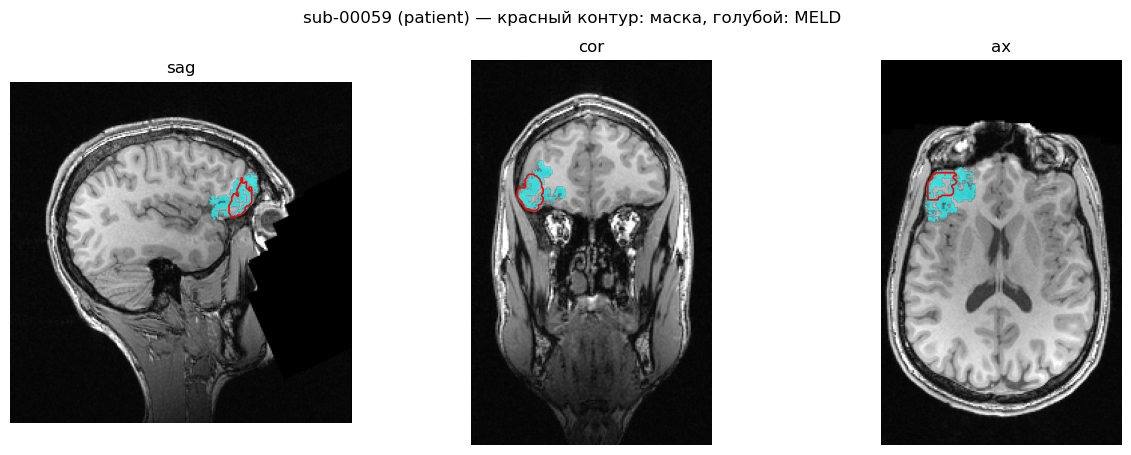

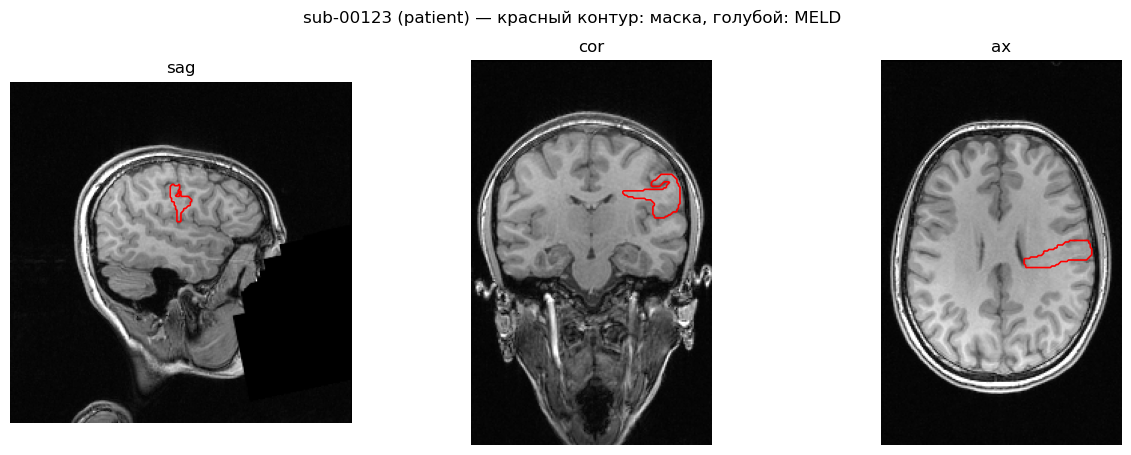

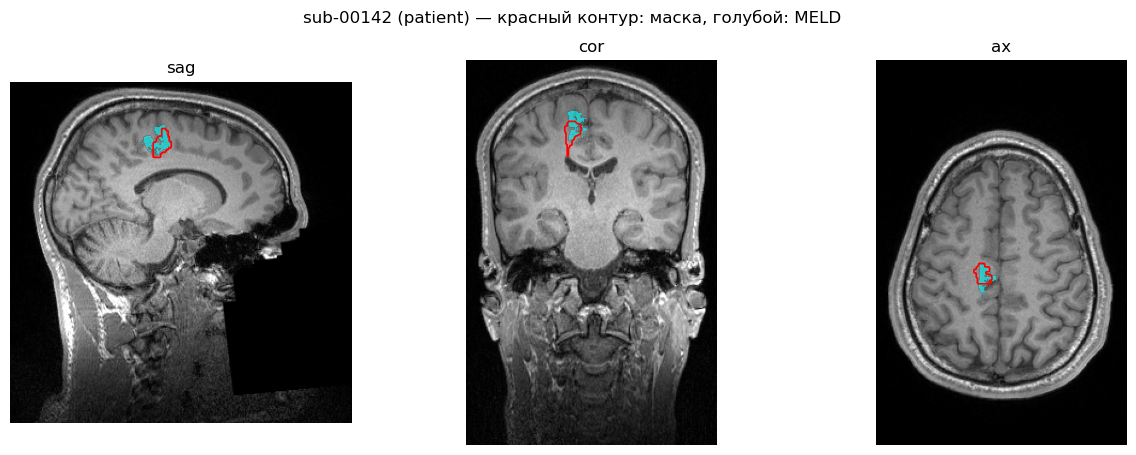

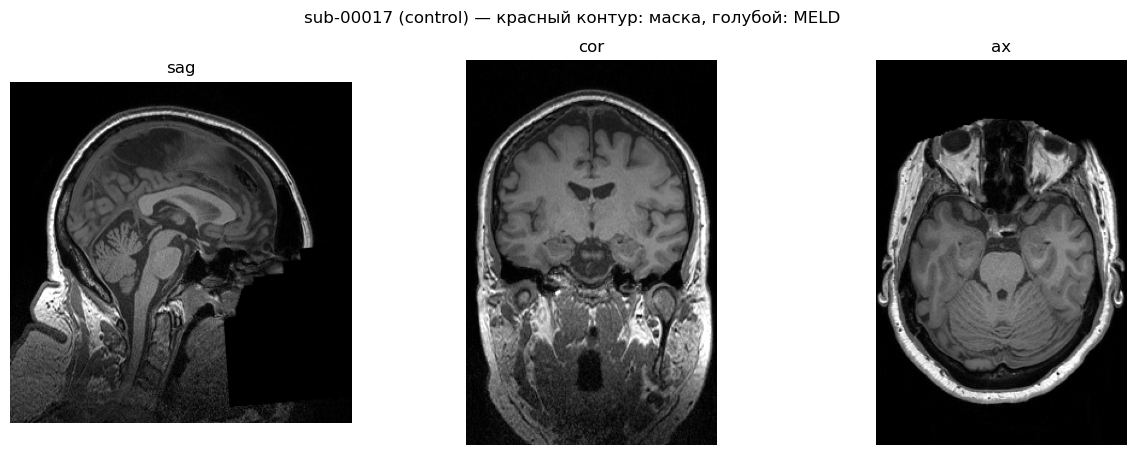

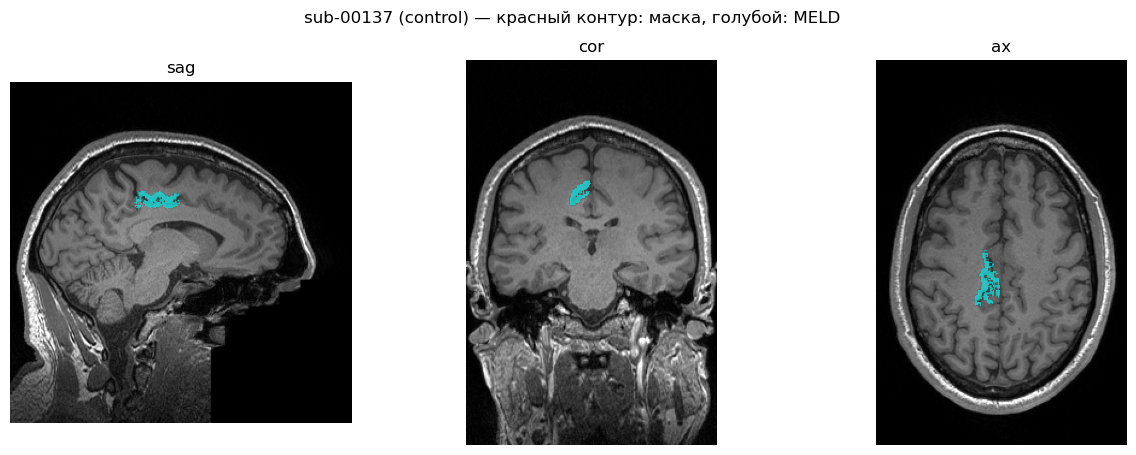

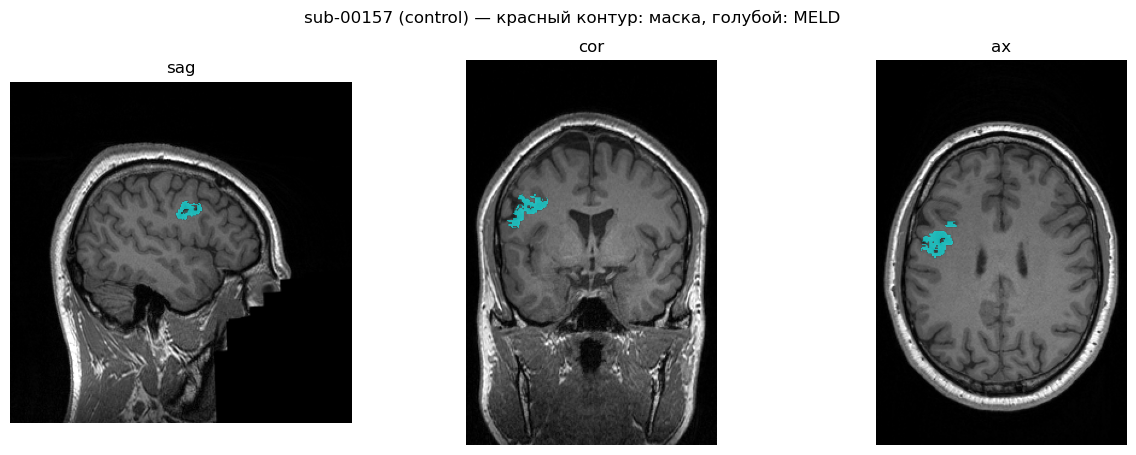

PDF-отчёты MELD: ['/home/trocinskayayv/projects/mri/meld_data/output/predictions_reports/B00017T1/reports/MELD_report_B00017T1.pdf', '/home/trocinskayayv/projects/mri/meld_data/output/predictions_reports/B00059T1/reports/MELD_report_B00059T1.pdf', '/home/trocinskayayv/projects/mri/meld_data/output/predictions_reports/B00123T1/reports/MELD_report_B00123T1.pdf', '/home/trocinskayayv/projects/mri/meld_data/output/predictions_reports/B00137T1/reports/MELD_report_B00137T1.pdf', '/home/trocinskayayv/projects/mri/meld_data/output/predictions_reports/B00142T1/reports/MELD_report_B00142T1.pdf', '/home/trocinskayayv/projects/mri/meld_data/output/predictions_reports/B00157T1/reports/MELD_report_B00157T1.pdf']


In [14]:
import matplotlib
import matplotlib.pyplot as plt

def show_subject(r, save=True):
    t1img = nib.load(r.t1)
    t1 = np.asanyarray(t1img.dataobj).astype(float)
    labels, _ = load_prediction(r.meld_id, t1img)
    roi = None
    if r.group == "patient" and r.roi:
        roi = load_on_grid(roi_to_t1(r)[0], t1img) > 0
    focus = roi if (roi is not None and roi.any()) else (labels > 0)
    c = [int(x) for x in (ndimage.center_of_mass(focus) if focus.any() else np.array(t1.shape) / 2)]
    vmax = np.percentile(t1, 99.5)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for i, (sl, name) in enumerate([(np.s_[c[0], :, :], "sag"), (np.s_[:, c[1], :], "cor"), (np.s_[:, :, c[2]], "ax")]):
        ax[i].imshow(np.rot90(t1[sl]), cmap="gray", vmax=vmax)
        pr = np.rot90(labels[sl] > 0)
        ax[i].imshow(np.ma.masked_where(~pr, pr), cmap="cool", alpha=0.6)
        if roi is not None:
            ax[i].contour(np.rot90(roi[sl]), levels=[0.5], colors="red", linewidths=1.2)
        ax[i].set_title(name); ax[i].axis("off")
    fig.suptitle(f"{r.bids_id} ({r.group}) — красный контур: маска, голубой: MELD")
    if save:
        fig.savefig(WORK_DIR / "figures" / f"{r.meld_id}.png", dpi=110, bbox_inches="tight")
    plt.show()

for _, r in subjects.iterrows():
    if find_prediction(r.meld_id):
        show_subject(r)

print("PDF-отчёты MELD:", sorted(str(p) for p in PRED_ROOT.glob("*/reports/*.pdf"))[:20])

## 11. Завершение

In [16]:
guard.stop()